In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/Chattogram_Landmark_Dataset"

SPLIT_DIR = os.path.join(
    BASE_DIR,
    "06_train_val_test"
)

TRAIN_DIR = os.path.join(SPLIT_DIR, "train")
VAL_DIR = os.path.join(SPLIT_DIR, "val")
TEST_DIR = os.path.join(SPLIT_DIR, "test")

MODEL_DIR = os.path.join(
    BASE_DIR,
    "07_models",
    "MobileNetV3Large"
)

RESULT_DIR = os.path.join(
    BASE_DIR,
    "08_results",
    "MobileNetV3Large"
)

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

print("Train:", TRAIN_DIR)
print("Validation:", VAL_DIR)
print("Test:", TEST_DIR)
print("Model output:", MODEL_DIR)
print("Results output:", RESULT_DIR)

Train: /content/drive/MyDrive/Chattogram_Landmark_Dataset/06_train_val_test/train
Validation: /content/drive/MyDrive/Chattogram_Landmark_Dataset/06_train_val_test/val
Test: /content/drive/MyDrive/Chattogram_Landmark_Dataset/06_train_val_test/test
Model output: /content/drive/MyDrive/Chattogram_Landmark_Dataset/07_models/MobileNetV3Large
Results output: /content/drive/MyDrive/Chattogram_Landmark_Dataset/08_results/MobileNetV3Large


In [ ]:
import os
import json
import random
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import (
    mobilenet_v3_large,
    MobileNet_V3_Large_Weights
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 42


In [ ]:
def get_class_names(root_dir):

    class_names = set()

    for district in sorted(os.listdir(root_dir)):

        district_path = os.path.join(root_dir, district)

        if not os.path.isdir(district_path):
            continue

        for landmark in sorted(os.listdir(district_path)):

            landmark_path = os.path.join(
                district_path,
                landmark
            )

            if os.path.isdir(landmark_path):
                class_names.add(landmark)

    return sorted(class_names)


class_names = get_class_names(TRAIN_DIR)

NUM_CLASSES = len(class_names)

class_to_idx = {
    name: idx
    for idx, name in enumerate(class_names)
}

idx_to_class = {
    idx: name
    for name, idx in class_to_idx.items()
}

print("Number of classes:", NUM_CLASSES)

for idx, name in idx_to_class.items():
    print(f"{idx:2d} → {name}")

Number of classes: 58
 0 → Adinath_Temple
 1 → Alutila_Cave
 2 → Anderkilla_Shahi_Jame_Mosque
 3 → Anderson_Canal
 4 → Arifail_Mosque
 5 → Bajra_Shahi_Mosque
 6 → Banshbaria_Beach
 7 → Batali_Hill
 8 → Bayazid_Bostami_Shrine
 9 → Boga_Lake
10 → Central_Railway_Building
11 → Chandanpura_Mosque
12 → Chandpur_Stadium
13 → Chandranath_Hill
14 → Chandranath_Temple
15 → Chattogram_Central_Shaheed_Minar
16 → Chattogram_Court_Building
17 → Chattogram_Railway_Station
18 → Chattogram_War_Cemetery
19 → Chattogram_Zoo
20 → Cheragi_Pahar
21 → Chimbuk_Hill
22 → Comilla_Cantonment_War_Cemetery
23 → Coxs_Bazar_Beach
24 → Dalal_Bazar_Jamindar_Bari
25 → Dharmasagar_Dighi
26 → Dulahazara_Safari_Park
27 → Ethnological_Museum
28 → Foys_Lake
29 → Golden_Temple_Bandarban
30 → Guliakhali_Beach
31 → Haripur_Barendra_Bari
32 → Himchari
33 → Inani_Beach
34 → Itakhola_Mura
35 → Jamboree_Park
36 → Kalurghat_Bridge
37 → Kaptai_Lake
38 → Keokradong
39 → Kutubdia_Island
40 → Lalmai_Hills
41 → Maheshkhali
42 → Mainama

In [ ]:
class_mapping = {
    "class_to_idx": class_to_idx,
    "idx_to_class": {
        str(k): v
        for k, v in idx_to_class.items()
    }
}

mapping_path = os.path.join(
    MODEL_DIR,
    "class_mapping.json"
)

with open(mapping_path, "w") as f:
    json.dump(
        class_mapping,
        f,
        indent=4
    )

print("Class mapping saved to:")
print(mapping_path)

Class mapping saved to:
/content/drive/MyDrive/Chattogram_Landmark_Dataset/07_models/MobileNetV3Large/class_mapping.json


In [ ]:
class LandmarkDataset(Dataset):

    def __init__(
        self,
        root_dir,
        class_to_idx,
        transform=None
    ):

        self.root_dir = root_dir
        self.class_to_idx = class_to_idx
        self.transform = transform

        self.samples = []

        for district in sorted(os.listdir(root_dir)):

            district_path = os.path.join(
                root_dir,
                district
            )

            if not os.path.isdir(district_path):
                continue

            for landmark in sorted(os.listdir(district_path)):

                landmark_path = os.path.join(
                    district_path,
                    landmark
                )

                if not os.path.isdir(landmark_path):
                    continue

                if landmark not in class_to_idx:
                    continue

                label = class_to_idx[landmark]

                for filename in sorted(
                    os.listdir(landmark_path)
                ):

                    if filename.lower().endswith(
                        (
                            ".jpg",
                            ".jpeg",
                            ".png",
                            ".webp"
                        )
                    ):

                        image_path = os.path.join(
                            landmark_path,
                            filename
                        )

                        self.samples.append(
                            (image_path, label)
                        )

        print(
            f"Loaded {len(self.samples)} images from "
            f"{root_dir}"
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):

        image_path, label = self.samples[index]

        try:

            image = Image.open(
                image_path
            ).convert("RGB")

        except Exception as e:

            print(
                f"Error loading image: {image_path}"
            )

            raise e

        if self.transform:
            image = self.transform(image)

        return image, label

In [ ]:
train_transform = transforms.Compose([

    transforms.RandomResizedCrop(
        224,
        scale=(0.70, 1.0),
        ratio=(0.85, 1.15)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=15
    ),

    transforms.ColorJitter(
        brightness=0.25,
        contrast=0.25,
        saturation=0.25,
        hue=0.05
    ),

    transforms.RandomApply(
        [
            transforms.GaussianBlur(
                kernel_size=3
            )
        ],
        p=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),

    transforms.RandomErasing(
        p=0.25,
        scale=(0.02, 0.12),
        ratio=(0.3, 3.3)
    )
])


val_test_transform = transforms.Compose([

    transforms.Resize(
        (256, 256)
    ),

    transforms.CenterCrop(
        224
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Transforms created.")

Transforms created.


In [ ]:
train_dataset = LandmarkDataset(
    TRAIN_DIR,
    class_to_idx,
    transform=train_transform
)

val_dataset = LandmarkDataset(
    VAL_DIR,
    class_to_idx,
    transform=val_test_transform
)

test_dataset = LandmarkDataset(
    TEST_DIR,
    class_to_idx,
    transform=val_test_transform
)

Loaded 1488 images from /content/drive/MyDrive/Chattogram_Landmark_Dataset/06_train_val_test/train
Loaded 321 images from /content/drive/MyDrive/Chattogram_Landmark_Dataset/06_train_val_test/val
Loaded 328 images from /content/drive/MyDrive/Chattogram_Landmark_Dataset/06_train_val_test/test


In [ ]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 47
Validation batches: 11
Test batches: 11


In [ ]:
images, labels = next(iter(train_loader))

print("Image shape:", images.shape)
print("Labels shape:", labels.shape)

print("Example labels:")
print(labels[:10])

Image shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Example labels:
tensor([42,  7, 10,  1,  0, 27,  1, 43, 50, 33])


In [ ]:
weights = MobileNet_V3_Large_Weights.DEFAULT

model = mobilenet_v3_large(
    weights=weights
)

print(model)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 118MB/s]


MobileNetV3(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
        )
      )
    )
    (2): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 64, kernel_size=(1, 1), stride=(1, 1), bi

In [ ]:
print("Original classifier:")
print(model.classifier)

Original classifier:
Sequential(
  (0): Linear(in_features=960, out_features=1280, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1280, out_features=1000, bias=True)
)


In [ ]:
in_features = model.classifier[-1].in_features

model.classifier = nn.Sequential(

    nn.Linear(
        in_features,
        1280
    ),

    nn.Hardswish(),

    nn.Dropout(
        p=0.40
    ),

    nn.Linear(
        1280,
        NUM_CLASSES
    )
)

print("\nNew classifier:")
print(model.classifier)


New classifier:
Sequential(
  (0): Linear(in_features=1280, out_features=1280, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.4, inplace=False)
  (3): Linear(in_features=1280, out_features=58, bias=True)
)


In [ ]:
for param in model.features.parameters():
    param.requires_grad = False

for param in model.classifier.parameters():
    param.requires_grad = True

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

print(
    "Trainable parameters:",
    trainable_params
)

print(
    "Total parameters:",
    total_params
)

Trainable parameters: 1713978
Total parameters: 4685930


In [ ]:
criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)

print("Loss function:")
print(criterion)

Loss function:
CrossEntropyLoss()


In [ ]:
optimizer = optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=3e-4,
    weight_decay=1e-3
)

print("Optimizer:", optimizer)

Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0003
    maximize: False
    weight_decay: 0.001
)


In [ ]:
if torch.cuda.is_available():

    scaler = torch.amp.GradScaler(
        "cuda"
    )

else:

    scaler = None

print("Mixed precision enabled:",
      scaler is not None)

Mixed precision enabled: True


In [ ]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device,
    scaler
):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        # Explicitly keep input images FLOAT32
        images = images.to(
            device=device,
            dtype=torch.float32,
            non_blocking=True
        )

        labels = labels.to(
            device=device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        # ====================================================
        # CUDA MIXED PRECISION
        # ====================================================

        if device.type == "cuda":

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            scaler.step(optimizer)
            scaler.update()

        # ====================================================
        # CPU
        # ====================================================

        else:

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

        # ====================================================
        # METRICS
        # ====================================================

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        total += labels.size(0)

        correct += (
            predictions == labels
        ).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [ ]:
def validate(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            running_loss += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(
                dim=1
            )

            total += labels.size(0)

            correct += (
                predictions == labels
            ).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision.models import (
    mobilenet_v3_large,
    MobileNet_V3_Large_Weights
)

# ============================================================
# RESET MOBILENETV3-LARGE
# ============================================================

weights = MobileNet_V3_Large_Weights.DEFAULT

model = mobilenet_v3_large(weights=weights)

# IMPORTANT:
# MobileNetV3-Large outputs 960 features before the classifier
in_features = model.classifier[0].in_features

print("MobileNet classifier input features:", in_features)

# Expected:
# MobileNet classifier input features: 960

model.classifier = nn.Sequential(
    nn.Linear(in_features, 1280),
    nn.Hardswish(),
    nn.Dropout(p=0.40),
    nn.Linear(1280, NUM_CLASSES)
)

# ============================================================
# FREEZE BACKBONE FOR STAGE 1
# ============================================================

for param in model.features.parameters():
    param.requires_grad = False

for param in model.classifier.parameters():
    param.requires_grad = True

# Move model to GPU
model = model.to(device)

# ============================================================
# LOSS
# ============================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)

# ============================================================
# OPTIMIZER
# ============================================================

optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=3e-4,
    weight_decay=1e-3
)

# ============================================================
# MIXED PRECISION
# ============================================================

if device.type == "cuda":
    scaler = torch.amp.GradScaler("cuda")
else:
    scaler = None

print("Model reset successfully.")
print("Number of classes:", NUM_CLASSES)

MobileNet classifier input features: 960
Model reset successfully.
Number of classes: 58


In [ ]:
# ============================================================
# ONE-BATCH FORWARD TEST
# ============================================================

model.eval()

images, labels = next(iter(train_loader))

print("CPU image dtype:", images.dtype)
print("CPU image shape:", images.shape)

images = images.to(
    device=device,
    dtype=torch.float32
)

labels = labels.to(device)

print("GPU image dtype:", images.dtype)
print("Model parameter dtype:", next(model.parameters()).dtype)

with torch.no_grad():

    if device.type == "cuda":

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(images)

    else:
        outputs = model(images)

print("Output shape:", outputs.shape)

CPU image dtype: torch.float32
CPU image shape: torch.Size([32, 3, 224, 224])
GPU image dtype: torch.float32
Model parameter dtype: torch.float32
Output shape: torch.Size([32, 58])


In [ ]:
def validate_one_epoch(
    model,
    loader,
    criterion,
    device
):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            # Keep images float32
            images = images.to(
                device=device,
                dtype=torch.float32,
                non_blocking=True
            )

            labels = labels.to(
                device=device,
                non_blocking=True
            )

            # Mixed precision for validation
            if device.type == "cuda":

                with torch.amp.autocast(
                    device_type="cuda",
                    dtype=torch.float16
                ):
                    outputs = model(images)
                    loss = criterion(outputs, labels)

            else:

                outputs = model(images)
                loss = criterion(outputs, labels)

            # Metrics
            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)

            correct += (
                predictions == labels
            ).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [ ]:
print("=" * 70)
print("MOBILENETV3-LARGE — STAGE 1")
print("=" * 70)

STAGE1_EPOCHS = 5

for epoch in range(STAGE1_EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device,
        scaler
    )

    val_loss, val_acc = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    print(
        f"Epoch {epoch+1}/{STAGE1_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

MOBILENETV3-LARGE — STAGE 1
Epoch 1/5 | Train Loss: 3.5266 | Train Acc: 0.3078 | Val Loss: 3.3535 | Val Acc: 0.3240
Epoch 2/5 | Train Loss: 3.1421 | Train Acc: 0.3690 | Val Loss: 3.0911 | Val Acc: 0.3364
Epoch 3/5 | Train Loss: 2.8772 | Train Acc: 0.4173 | Val Loss: 2.9280 | Val Acc: 0.3583
Epoch 4/5 | Train Loss: 2.6835 | Train Acc: 0.4577 | Val Loss: 2.8404 | Val Acc: 0.3738
Epoch 5/5 | Train Loss: 2.5474 | Train Acc: 0.4859 | Val Loss: 2.7606 | Val Acc: 0.4019


In [ ]:
# ============================================================
# MOBILENETV3-LARGE — STAGE 2 SETUP
# ============================================================

print("=" * 70)
print("MOBILENETV3-LARGE — STAGE 2 SETUP")
print("=" * 70)

# Freeze everything first
for param in model.features.parameters():
    param.requires_grad = False

# Unfreeze the last 4 feature blocks
for param in model.features[-4:].parameters():
    param.requires_grad = True

# Classifier remains trainable
for param in model.classifier.parameters():
    param.requires_grad = True


# Count trainable parameters
trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(
    f"Trainable percentage: "
    f"{100 * trainable_params / total_params:.2f}%"
)

MOBILENETV3-LARGE — STAGE 2 SETUP
Total parameters:     4,276,330
Trainable parameters: 3,483,842
Trainable percentage: 81.47%


In [ ]:
# ============================================================
# STAGE 2 OPTIMIZER
# ============================================================

optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=5e-5,
    weight_decay=1e-3
)

# Cosine learning-rate schedule
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=20,
    eta_min=1e-6
)

print("Stage 2 optimizer ready.")
print("Initial learning rate:", optimizer.param_groups[0]["lr"])

Stage 2 optimizer ready.
Initial learning rate: 5e-05


In [ ]:
# ============================================================
# STAGE 2 SETTINGS
# ============================================================

STAGE2_EPOCHS = 20
PATIENCE = 5

best_val_acc = 0.0
epochs_without_improvement = 0

BEST_MODEL_PATH = (
    "/content/drive/MyDrive/"
    "Chattogram_Landmark_Dataset/"
    "07_models/MobileNetV3Large/"
    "mobilenetv3_best.pth"
)

print("Stage 2 configured.")
print("Maximum epochs:", STAGE2_EPOCHS)
print("Early stopping patience:", PATIENCE)

Stage 2 configured.
Maximum epochs: 20
Early stopping patience: 5


In [ ]:
# ============================================================
# MOBILENETV3-LARGE — STAGE 2
# ============================================================

print("=" * 70)
print("MOBILENETV3-LARGE — STAGE 2")
print("=" * 70)

stage2_history = []

for epoch in range(STAGE2_EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device,
        scaler
    )

    val_loss, val_acc = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    # Update learning rate
    scheduler.step()

    current_lr = optimizer.param_groups[0]["lr"]

    stage2_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "lr": current_lr
    })

    print(
        f"Epoch {epoch+1:02d}/{STAGE2_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"LR: {current_lr:.2e}"
    )

    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if val_acc > best_val_acc:

        best_val_acc = val_acc
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "val_acc": val_acc,
                "val_loss": val_loss,
                "num_classes": NUM_CLASSES
            },
            BEST_MODEL_PATH
        )

        print(
            f"  ✓ Best model saved "
            f"(Val Acc: {val_acc:.4f})"
        )

    else:

        epochs_without_improvement += 1

        print(
            f"  No improvement "
            f"({epochs_without_improvement}/{PATIENCE})"
        )

    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if epochs_without_improvement >= PATIENCE:

        print()
        print(
            f"Early stopping triggered at "
            f"epoch {epoch+1}."
        )

        break

print()
print("=" * 70)
print("STAGE 2 COMPLETE")
print("=" * 70)
print(f"Best validation accuracy: {best_val_acc:.4f}")
print(
    f"Best validation accuracy: "
    f"{best_val_acc * 100:.2f}%"
)

MOBILENETV3-LARGE — STAGE 2
Epoch 01/20 | Train Loss: 2.1866 | Train Acc: 0.5544 | Val Loss: 2.6221 | Val Acc: 0.4112 | LR: 4.88e-05
  ✓ Best model saved (Val Acc: 0.4112)
Epoch 02/20 | Train Loss: 2.1352 | Train Acc: 0.5679 | Val Loss: 2.5953 | Val Acc: 0.4299 | LR: 4.73e-05
  ✓ Best model saved (Val Acc: 0.4299)
Epoch 03/20 | Train Loss: 2.0377 | Train Acc: 0.5995 | Val Loss: 2.5624 | Val Acc: 0.4361 | LR: 4.53e-05
  ✓ Best model saved (Val Acc: 0.4361)
Epoch 04/20 | Train Loss: 1.9533 | Train Acc: 0.6310 | Val Loss: 2.5175 | Val Acc: 0.4704 | LR: 4.28e-05
  ✓ Best model saved (Val Acc: 0.4704)
Epoch 05/20 | Train Loss: 1.8675 | Train Acc: 0.6505 | Val Loss: 2.5055 | Val Acc: 0.4642 | LR: 3.99e-05
  No improvement (1/5)
Epoch 06/20 | Train Loss: 1.8400 | Train Acc: 0.6539 | Val Loss: 2.4898 | Val Acc: 0.4829 | LR: 3.66e-05
  ✓ Best model saved (Val Acc: 0.4829)
Epoch 07/20 | Train Loss: 1.7775 | Train Acc: 0.6915 | Val Loss: 2.4748 | Val Acc: 0.4829 | LR: 3.31e-05
  No improvement (1

In [ ]:
# ============================================================
# LOAD BEST MOBILENETV3-LARGE CHECKPOINT
# ============================================================

BEST_MODEL_PATH = (
    "/content/drive/MyDrive/"
    "Chattogram_Landmark_Dataset/"
    "07_models/MobileNetV3Large/"
    "mobilenetv3_best.pth"
)

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

print("=" * 70)
print("BEST MOBILENETV3-LARGE CHECKPOINT LOADED")
print("=" * 70)

print("Saved epoch:",
      checkpoint["epoch"])

print(
    f"Validation accuracy: "
    f"{checkpoint['val_acc'] * 100:.2f}%"
)

print(
    f"Validation loss: "
    f"{checkpoint['val_loss']:.4f}"
)

BEST MOBILENETV3-LARGE CHECKPOINT LOADED
Saved epoch: 13
Validation accuracy: 50.78%
Validation loss: 2.4431


In [ ]:
# ============================================================
# TEST SET EVALUATION
# ============================================================

model.eval()

test_correct = 0
test_total = 0
test_loss_total = 0.0

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(
            device=device,
            dtype=torch.float32,
            non_blocking=True
        )

        labels = labels.to(
            device=device,
            non_blocking=True
        )

        if device.type == "cuda":

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                outputs = model(images)
                loss = criterion(
                    outputs,
                    labels
                )

        else:

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        predictions = outputs.argmax(
            dim=1
        )

        test_loss_total += (
            loss.item() * images.size(0)
        )

        test_total += labels.size(0)

        test_correct += (
            predictions == labels
        ).sum().item()

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

test_loss = (
    test_loss_total / test_total
)

test_accuracy = (
    test_correct / test_total
)

print("=" * 70)
print("MOBILENETV3-LARGE — TEST RESULTS")
print("=" * 70)

print(
    f"Test Loss: {test_loss:.4f}"
)

print(
    f"Test Accuracy: "
    f"{test_accuracy:.4f}"
)

print(
    f"Test Accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Test Samples: "
    f"{test_total}"
)

MOBILENETV3-LARGE — TEST RESULTS
Test Loss: 2.4390
Test Accuracy: 0.4970
Test Accuracy: 49.70%
Test Samples: 328


In [ ]:
from sklearn.metrics import classification_report

# Convert class_to_idx → index-to-class
idx_to_class = {v: k for k, v in class_to_idx.items()}
class_names = [idx_to_class[i] for i in range(NUM_CLASSES)]

print("=" * 90)
print("MOBILENETV3-LARGE — CLASSIFICATION REPORT")
print("=" * 90)

report = classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report)

MOBILENETV3-LARGE — CLASSIFICATION REPORT
                                  precision    recall  f1-score   support

                  Adinath_Temple     0.2857    0.3333    0.3077         6
                    Alutila_Cave     0.2500    0.2000    0.2222         5
    Anderkilla_Shahi_Jame_Mosque     0.4286    0.5000    0.4615         6
                  Anderson_Canal     0.6667    0.4000    0.5000         5
                  Arifail_Mosque     0.8000    1.0000    0.8889         4
              Bajra_Shahi_Mosque     1.0000    0.4000    0.5714         5
                Banshbaria_Beach     1.0000    0.3333    0.5000         6
                     Batali_Hill     0.3750    0.5000    0.4286         6
          Bayazid_Bostami_Shrine     0.5000    0.1667    0.2500         6
                       Boga_Lake     0.7500    0.5000    0.6000         6
        Central_Railway_Building     1.0000    0.3333    0.5000         6
              Chandanpura_Mosque     0.8571    1.0000    0.9231      

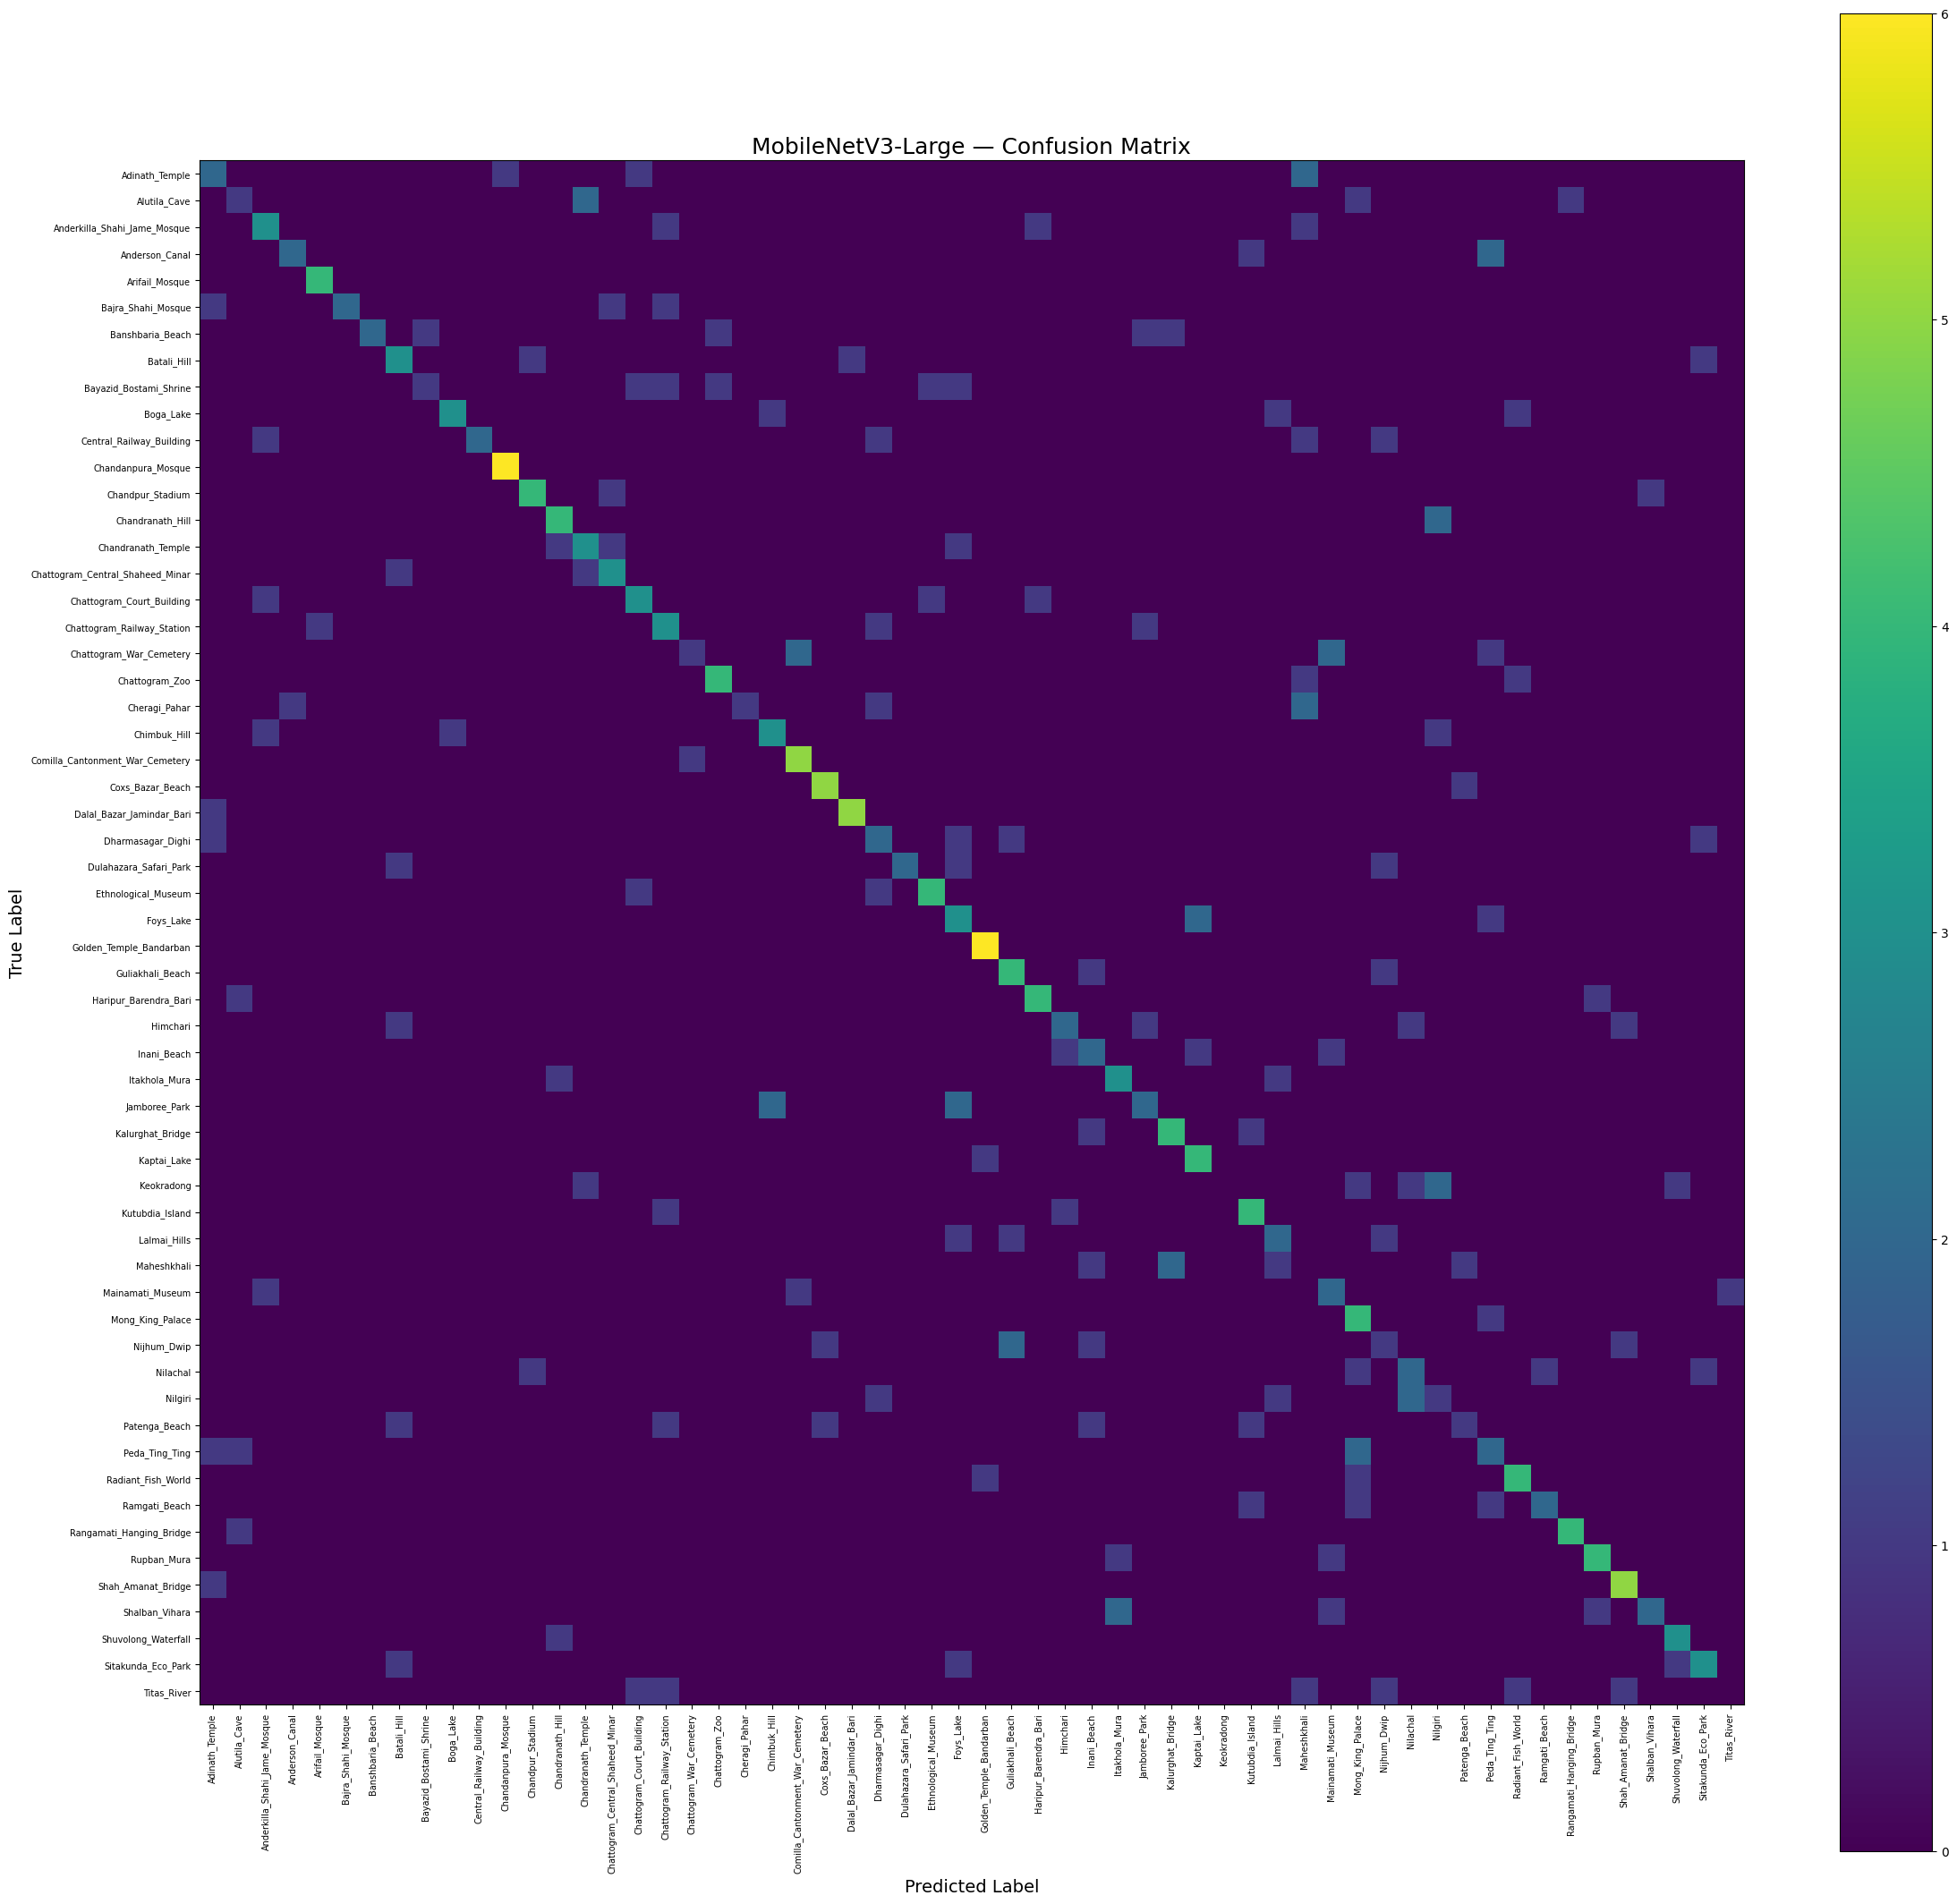

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(24, 22))

plt.imshow(cm, interpolation="nearest")
plt.title("MobileNetV3-Large — Confusion Matrix", fontsize=18)
plt.colorbar()

plt.xticks(
    np.arange(NUM_CLASSES),
    class_names,
    rotation=90,
    fontsize=7
)

plt.yticks(
    np.arange(NUM_CLASSES),
    class_names,
    fontsize=7
)

plt.xlabel("Predicted Label", fontsize=14)
plt.ylabel("True Label", fontsize=14)

plt.tight_layout()
plt.show()

In [ ]:
results_df = pd.DataFrame({

    "true_label": [
        idx_to_class[x]
        for x in all_labels
    ],

    "predicted_label": [
        idx_to_class[x]
        for x in all_predictions
    ]

})

results_df.to_csv(

    os.path.join(
        RESULT_DIR,
        "mobilenetv3_test_predictions.csv"
    ),

    index=False
)

print("MobileNetV3-Large predictions saved.")

MobileNetV3-Large predictions saved.


In [ ]:
history_df = pd.DataFrame(history)

history_df.to_csv(

    os.path.join(
        RESULT_DIR,
        "mobilenetv3_training_history.csv"
    ),

    index=False
)

print("MobileNetV3-Large training history saved.")

MobileNetV3-Large training history saved.
